In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Firm size and productivity: where does Italy's size structure stand, and how much of the gap does it carry?
Notebook 35 (regulation) and notebooks 08, 13 and 23 (sectors) left one question open: *inside* a sector, is Italy's productivity shortfall about the **average firm**, about a **tail of small firms**, or about **how employment is spread over firm sizes**? The firm-level dispersion statistics that answer this best (CompNet, IWH Halle) are not available to this project (access is for researchers with an institutional affiliation). This notebook uses what is public instead: the **Eurostat structural business statistics by employment size class** (`sbs_sc_sca_r2`, 2005-2020, and `sbs_sc_ovw`, 2021 onwards): for each country, year and NACE section, the number of enterprises, persons employed and value added in five disjoint classes (0-9, 10-19, 20-49, 50-249, 250+ persons).

**What it can and cannot do.** It gives the size *mix* and the *average* productivity of each class, so it can say how much of a gap is the mix of employment over sizes and how much is productivity within a size class. It cannot see the dispersion of firms inside a class (the CompNet question), nor which firms are missing: a country with the same class averages and a different distribution inside classes looks the same here.

**Design.** (1) Italy's employment shares and productivity by class, and its **rank among the EU27 members** (placebo ranking: Italy is one cluster, so no clustered test; the smallest two-sided p with n members is 2/n, so with about 23 members nothing can reach q < 0.05 and the results are orderings, as in notebook 41). (2) The **mix effect**: the log of Italy's productivity recomputed with the other members' median size mix over its actual one, with the same quantity for every member. (3) An **exact decomposition** of Italy's log gap to a reference (each of Germany, France, Spain, the Netherlands, and the median of the others) into `size_mix` (Italy's mix against the reference mix, at Italy's own class productivities) and `within` (Italy's class productivities against the reference's, at the reference mix). (4) The same by NACE section, and a sector-versus-within-sector split of the micro-firm share.

**Limits to keep in mind.** The statistical unit is the *enterprise* as each country's register defines it (a group split into legal units looks like many small firms); the persons are heads, not hours, and the productivity is value added at factor cost (2005-2020) or basic prices (2021 onwards) per person, so the two vintages are never combined. Euro levels are not compared across countries without a correction: the level comparisons use the GDP price level index of the country-year (an approximation for value added) and, per hour, the economy-wide hours per worker (AMECO), assumed equal in every class. The `size_mix` term is the same per head and per hour (a country-wide factor cancels in it); only `within` depends on the corrections. Class productivity differences mix selection (productive firms grow) and a causal advantage of scale, so the mix effect is an *accounting* number: moving employment between classes at class-average productivity is an upper bound of what a change of structure could do, not a forecast. Descriptive only.

In [2]:
from cifresignificative.studies.italy_productivity.analysis import size_class as SC
res = SC.run_size_all(); size = SC.load_size(); S1 = res["s1_structure"]; cl = SC.CLASSES
cov = S1.groupby(["vintage", "year"]).iso3.nunique().unstack(0); print("EU27 members with all five size classes (persons and value added) in the economy aggregate:"); display(cov.T.fillna(0).astype(int))
print("Italy has the five classes in:", {v: sorted(S1[(S1.vintage == v) & (S1.iso3 == "ITA")].year.astype(int)) for v in ("old", "new")})
raw = size[(size.iso3 == "ITA") & (size.vintage == "old") & (size.nace_r2 == SC.ECONOMY["old"]) & (size.year.isin([2015, 2016, 2017, 2019, 2020]))]
print("Italy, Eurostat flags of the size-class series by year (b = break in series):", raw.groupby("year").flag.agg(lambda f: sorted(set(f.dropna()))).to_dict())
print("EU27 members without the five classes in 2019 (old vintage):", sorted(set(EU27_ISO3) - set(S1[(S1.vintage == "old") & (S1.year == 2019)].iso3)))
print("members with a break flag in the 2019 economy aggregate:", int(S1[(S1.vintage == "old") & (S1.year == 2019)].broken.sum()))

EU27 members with all five size classes (persons and value added) in the economy aggregate:


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
vintage,,,,,,,,,,,,,,,
new,0,0,0,0,0,0,0,0,0,0,0,25,26,27,26
old,13,17,18,19,19,20,21,19,21,23,20,0,0,0,0


Italy has the five classes in: {'old': [2013, 2015, 2016, 2019, 2020], 'new': [2021, 2022, 2023, 2024]}
Italy, Eurostat flags of the size-class series by year (b = break in series): {2015: [], 2016: [], 2017: ['b'], 2019: [], 2020: []}
EU27 members without the five classes in 2019 (old vintage): ['AUT', 'CYP', 'DNK', 'PRT']
members with a break flag in the 2019 economy aggregate: 1


## Italy's size structure in 2019 (the main snapshot)
2019 is the last year before the pandemic with the most members (23 of 27); 2020 is reported below. Each share and relative productivity is a ratio inside the country, so no price or currency correction enters.

,"employment share, Italy",median others,min others,max others,"productivity / own total, Italy",median others,"enterprises, Italy","enterprise share, Italy"
size_emp,,,,,,,,
0-9,0.419,0.304,0.171,0.441,0.605,0.701,3414226.0,0.944
10-19,0.110,0.091,0.056,0.120,0.893,0.823,127154.0,0.035
20-49,0.099,0.114,0.080,0.142,1.098,0.972,50956.0,0.014
50-249,0.133,0.187,0.128,0.242,1.337,1.097,20939.0,0.006
GE250,0.239,0.315,0.172,0.487,1.513,1.289,3641.0,0.001


members: 23 | Italy persons employed in the five classes: 15198230 | mean persons per enterprise, Italy: 4.2


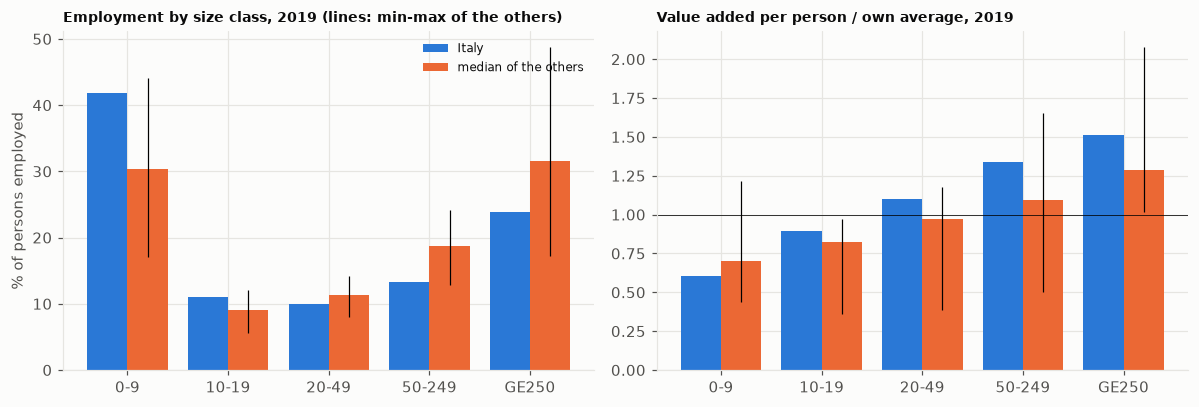

In [3]:
t = SC.class_table(size, "old"); t = t[t.year == 2019]
P = t.pivot(index="iso3", columns="size_emp", values="persons")[cl]; V = t.pivot(index="iso3", columns="size_emp", values="va_meur")[cl]; E = t.pivot(index="iso3", columns="size_emp", values="enterprises")[cl]
Sh = P.div(P.sum(axis=1), axis=0); rel = (V / P).div(V.sum(axis=1) / P.sum(axis=1), axis=0)
tab = pd.DataFrame({"employment share, Italy": Sh.loc["ITA"], "median others": Sh.drop("ITA").median(), "min others": Sh.drop("ITA").min(), "max others": Sh.drop("ITA").max(),
                    "productivity / own total, Italy": rel.loc["ITA"], "median others ": rel.drop("ITA").median(), "enterprises, Italy": E.loc["ITA"], "enterprise share, Italy": E.loc["ITA"] / E.loc["ITA"].sum()})
display(tab.round(3)); print("members:", len(Sh), "| Italy persons employed in the five classes:", int(P.loc["ITA"].sum()), "| mean persons per enterprise, Italy:", round(float(P.loc["ITA"].sum() / E.loc["ITA"].sum()), 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); x = np.arange(5); o = Sh.drop("ITA")
ax[0].bar(x - .2, Sh.loc["ITA"] * 100, .4, color=ITALY_C, label="Italy"); ax[0].bar(x + .2, o.median() * 100, .4, color=EU_C, label="median of the others"); ax[0].errorbar(x + .2, o.median() * 100, yerr=[(o.median() - o.min()) * 100, (o.max() - o.median()) * 100], fmt="none", ecolor="k", lw=.8)
ax[0].set_xticks(x, cl); ax[0].set_ylabel("% of persons employed"); ax[0].set_title("Employment by size class, 2019 (lines: min-max of the others)", fontsize=9); ax[0].legend(fontsize=8)
r_o = rel.drop("ITA"); ax[1].bar(x - .2, rel.loc["ITA"], .4, color=ITALY_C); ax[1].bar(x + .2, r_o.median(), .4, color=EU_C); ax[1].errorbar(x + .2, r_o.median(), yerr=[r_o.median() - r_o.min(), r_o.max() - r_o.median()], fmt="none", ecolor="k", lw=.8)
ax[1].axhline(1, color="k", lw=.5); ax[1].set_xticks(x, cl); ax[1].set_title("Value added per person / own average, 2019", fontsize=9); plt.tight_layout(); plt.show()

## Where Italy ranks, and the primary family
The statistics are the micro (0-9) and large (250+) employment shares, the productivity of those two classes relative to the country's own average, the large-to-micro **gradient** log(productivity of 250+ / 0-9), the **mix effect**, and the mean persons per enterprise. `rank` 1 = the highest value among the members with data. The primary family is these seven statistics in 2019; BH q is computed over it, other years carry no q.

In [4]:
pos = res["s2_position"]; main = pos[pos.primary].set_index("statistic")
print("2019, old vintage, economy aggregate (B-N without K, repairs included): Italy against the others; BH q over the", len(main), "statistics:"); display(main[["n", "italy", "median_others", "rank", "p", "q_value"]].round(3))
print("smallest attainable two-sided p with", int(main.n.min()), "members:", round(2 / main.n.min(), 3), "| smallest q in the family:", round(float(main.q_value.min()), 3), "| statistics with q <= 0.05:", int((main.q_value <= 0.05).sum()))
keep = ["micro_share", "large_share", "gradient", "mix_effect"]; o = pos[~pos.primary & pos.statistic.isin(keep)]
print("rank of Italy in the other years (not primary, no q; the old and new vintages are different series: compare ranks within a vintage only):"); display(pd.concat([pos[pos.primary & pos.statistic.isin(keep)], o]).pivot_table(index=["vintage", "year"], columns="statistic", values="rank")[keep])
print("members with data per year, same table:"); display(pos[pos.statistic == "micro_share"].set_index(["vintage", "year"])[["n", "n_break", "italy_break"]])
print("Italy's micro share of employment by year (old vintage has Eurostat break flag in 2017: 2013-2016 and 2019 are not one series; new vintage from 2021):", pos[pos.statistic == "micro_share"].set_index(["vintage", "year"]).italy.round(3).to_dict())

2019, old vintage, economy aggregate (B-N without K, repairs included): Italy against the others; BH q over the 7 statistics:


,n,italy,median_others,rank,p,q_value
statistic,,,,,,
micro_share,23,0.419,0.304,3,0.261,0.435
large_share,23,0.239,0.315,19,0.435,0.435
micro_lp_rel,23,0.605,0.701,20,0.348,0.435
large_lp_rel,23,1.513,1.289,4,0.348,0.435
gradient,23,0.917,0.630,5,0.435,0.435
mix_effect,23,0.100,0.009,2,0.174,0.435
mean_firm_size,23,4.202,5.308,20,0.348,0.435


smallest attainable two-sided p with 23 members: 0.087 | smallest q in the family: 0.435 | statistics with q <= 0.05: 0
rank of Italy in the other years (not primary, no q; the old and new vintages are different series: compare ranks within a vintage only):


statistic     micro_share  large_share  gradient  mix_effect
vintage year                                                
new     2021          3.0         21.0       6.0         3.0
        2022          3.0         22.0       7.0         3.0
        2023          4.0         22.0       8.0         4.0
        2024          4.0         19.0       9.0         3.0
old     2013          1.0         19.0       2.0         1.0
        2015          1.0         18.0       4.0         1.0
        2016          1.0         20.0       4.0         1.0
        2019          3.0         19.0       5.0         2.0
        2020          3.0         17.0       4.0         2.0

members with data per year, same table:


n  n_break  italy_break
vintage year                          
old     2013  19        0        False
        2015  20        1        False
        2016  21        1        False
        2019  23        1        False
        2020  20        0        False
new     2021  25        3        False
        2022  26        0        False
        2023  27        0        False
        2024  26        0        False

Italy's micro share of employment by year (old vintage has Eurostat break flag in 2017: 2013-2016 and 2019 are not one series; new vintage from 2021): {('old', 2013): 0.464, ('old', 2015): 0.456, ('old', 2016): 0.449, ('old', 2019): 0.419, ('old', 2020): 0.425, ('new', 2021): 0.426, ('new', 2022): 0.418, ('new', 2023): 0.408, ('new', 2024): 0.399}


## The mix effect: what Italy's productivity would be with the other members' size mix
For each member, the log of its productivity recomputed with the median employment shares of the *other* members (renormalised) and its own class productivities, over its actual productivity: positive = the member's mix costs it. The calculation uses only the member's own class productivities, so prices, currency and hours do not enter.

,Italy share,typical share (median of the others),"difference, pp","Italy productivity, kEUR/person",contribution to the change of productivity
size_emp,,,,,
0-9,0.419,0.300,-11.845,30.699,-0.072
10-19,0.110,0.090,-1.945,45.311,-0.017
20-49,0.099,0.113,1.331,55.740,0.015
50-249,0.133,0.185,5.168,67.853,0.069
GE250,0.239,0.312,7.290,76.775,0.110


sum of the contributions: 0.105 = exp(mix effect) - 1; mix effect (log): 0.0998
mix effect, 2019, all members (log points; positive = the mix costs the country):


iso3,FRA,DEU,SWE,ROU,FIN,NLD,CZE,EST,BEL,LTU,...,IRL,HUN,SVN,BGR,LVA,ESP,LUX,SVK,ITA,GRC
mix_effect,-0.06,-0.06,-0.048,-0.019,-0.015,-0.011,-0.011,-0.003,-0.001,0.003,...,0.014,0.018,0.019,0.02,0.027,0.033,0.038,0.089,0.1,0.238


Italy's mix effect leaving each other member out of the reference group: min 0.098 max 0.102 ( 22 members )
with the mean instead of the median of the others: {'italy': 0.103, 'rank': 2, 'n': 23}
Italy's mix effect against the mix of single countries (-size_mix; the same per head and per hour): {'DEU': 0.182, 'FRA': 0.187, 'ESP': 0.063, 'NLD': 0.129, 'typical': 0.1}


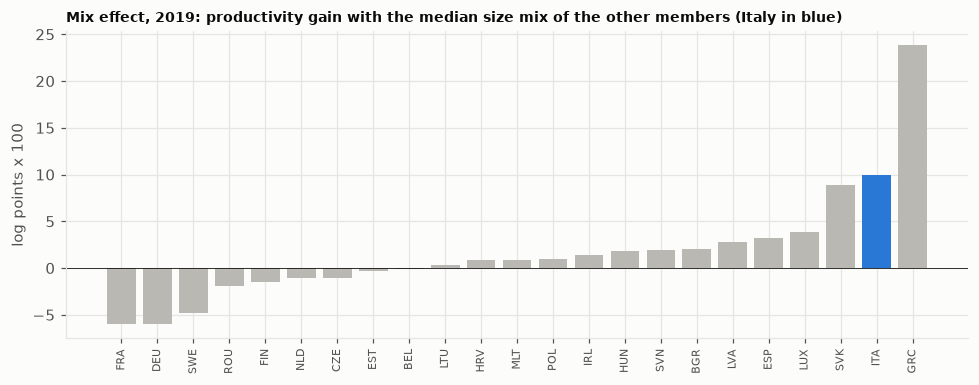

In [5]:
S19 = Sh.copy(); LP19 = (V / P * 1000).where((P > 0) & (V > 0)); typ = SC.others_mix(S19).loc["ITA"]; own = S19.loc["ITA"]; w = LP19.loc["ITA"]; base = float((own * w).sum())
contrib = pd.DataFrame({"Italy share": own, "typical share (median of the others)": typ, "difference, pp": (typ - own) * 100, "Italy productivity, kEUR/person": w, "contribution to the change of productivity": (typ - own) * w / base})
display(contrib.round(3)); print("sum of the contributions:", round(float(contrib.iloc[:, -1].sum()), 4), "= exp(mix effect) - 1; mix effect (log):", round(float(np.log(1 + contrib.iloc[:, -1].sum())), 4))
mx = S1[(S1.vintage == "old") & (S1.year == 2019)].set_index("iso3").mix_effect.dropna().sort_values()
print("mix effect, 2019, all members (log points; positive = the mix costs the country):"); display(mx.round(3).to_frame("mix_effect").T)
loo = res["s9_mix_leave_one_out"]; print("Italy's mix effect leaving each other member out of the reference group:", "min", round(float(loo.mix_effect.min()), 3), "max", round(float(loo.mix_effect.max()), 3), "(", len(loo), "members )")
print("with the mean instead of the median of the others:", res["s6_mean_mix"][["italy", "rank", "n"]].round(3).to_dict("records")[0])
gd = res["s8_gap_decomposition"]; g0 = gd[(gd.section == "economy") & (gd.basis == "hour")].set_index("reference")
print("Italy's mix effect against the mix of single countries (-size_mix; the same per head and per hour):", (-g0.size_mix).round(3).to_dict())
fig, ax = plt.subplots(figsize=(9, 3.6)); cols = [ITALY_C if c == "ITA" else PEER_C for c in mx.index]; ax.bar(mx.index, mx.values * 100, color=cols); ax.axhline(0, color="k", lw=.5); ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.set_ylabel("log points x 100"); ax.set_title("Mix effect, 2019: productivity gain with the median size mix of the other members (Italy in blue)", fontsize=9); plt.tight_layout(); plt.show()

## Levels and the exact gap decomposition
Levels are compared only after two corrections that are approximations: the GDP price level index of the country-year (EU27 = 100) and, for the per-hour basis, the economy-wide hours per worker (AMECO). Heads, not hours, are what the survey counts, so part-time work lowers a country's value added per head; the per-hour basis undoes this on average but not class by class. The decomposition is exact whatever the corrections: total = `size_mix` + `within`.

value added per person (head) and per hour, EUR at the EU27 price level, 2019, economy aggregate; ratio of Italy to the median of the others and to four peers:


n     italy  median_others  ratio_to_median  rank  ratio_DEU  \
basis size_emp                                                                  
head  0-9       23  30852.97       31697.52             0.97    13       0.80   
      10-19     23  45539.05       39344.38             1.16     5       1.15   
      20-49     23  56020.21       44731.95             1.25     4       1.26   
      50-249    23  68193.88       48045.37             1.42     3       1.27   
      GE250     23  77160.78       57460.74             1.34     4       1.11   
      total     23  51000.89       44782.82             1.14     9       0.93   
hour  0-9       23     18.36          18.75             0.98    12       0.65   
      10-19     23     27.10          21.64             1.25     9       0.94   
      20-49     23     33.34          22.81             1.46     5       1.03   
      50-249    23     40.58          26.01             1.56     4       1.04   
      GE250     23     45.92          32.13             1.43     6       0.91   
      total     23     30.35          24.26             1.25     9       0.76   

                ratio_FRA  ratio_ESP  ratio_NLD  
basis size_emp                                   
head  0-9            0.67       1.05       0.70  
      10-19          0.95       1.12       0.90  
      20-49          1.08       1.22       0.91  
      50-249         1.16       1.16       0.94  
      GE250          1.08       1.21       1.26  
      total          0.84       1.09       0.88  
hour  0-9            0.60       1.05       0.60  
      10-19          0.85       1.12       0.78  
      20-49          0.97       1.22       0.79  
      50-249         1.04       1.16       0.81  
      GE250          0.97       1.21       1.09  
      total          0.75       1.09       0.76

exact decomposition of Italy's log gap, economy aggregate (log points; total = size_mix + within; negative = Italy below the reference):


n  total  size_mix  within
basis reference                             
hour  DEU        23 -0.276    -0.182  -0.094
      FRA        23 -0.283    -0.187  -0.096
      ESP        23  0.085    -0.063   0.149
      NLD        23 -0.269    -0.129  -0.140
      typical    23  0.195    -0.100   0.294
head  DEU        23 -0.073    -0.182   0.109
      FRA        23 -0.172    -0.187   0.014
      ESP        23  0.087    -0.063   0.150
      NLD        23 -0.126    -0.129   0.003
      typical    23  0.127    -0.100   0.227

exact decomposition of Italy's log gap, manufacturing (C) (log points; total = size_mix + within; negative = Italy below the reference):


n  total  size_mix  within
basis reference                             
hour  DEU        25 -0.296    -0.221  -0.075
      FRA        25 -0.221    -0.198  -0.023
      ESP        25  0.008    -0.080   0.088
      NLD        25 -0.445    -0.087  -0.358
      typical    25  0.293    -0.141   0.435
head  DEU        25 -0.093    -0.221   0.128
      FRA        25 -0.110    -0.198   0.088
      ESP        25  0.009    -0.080   0.089
      NLD        25 -0.302    -0.087  -0.215
      typical    25  0.248    -0.141   0.390

exact decomposition of Italy's log gap, trade (G) (log points; total = size_mix + within; negative = Italy below the reference):


n  total  size_mix  within
basis reference                             
hour  DEU        25 -0.277    -0.260  -0.017
      FRA        25 -0.321    -0.240  -0.081
      ESP        25  0.088    -0.118   0.207
      NLD        25 -0.349    -0.235  -0.114
      typical    25  0.086    -0.170   0.256
head  DEU        25 -0.075    -0.260   0.185
      FRA        25 -0.210    -0.240   0.030
      ESP        25  0.090    -0.118   0.208
      NLD        25 -0.206    -0.235   0.029
      typical    25  0.089    -0.170   0.258

largest departure from the identity over all rows: 2.220446049250313e-16


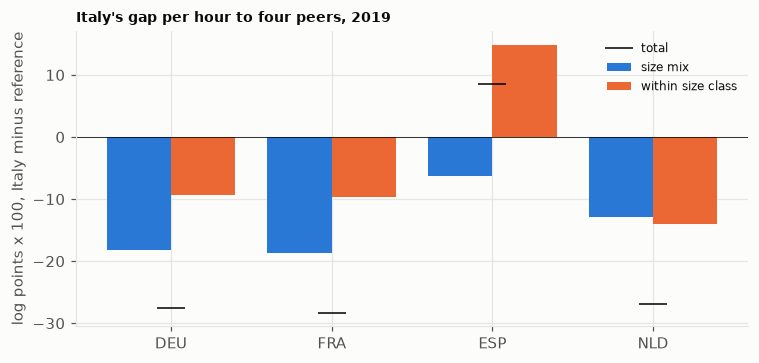

In [6]:
lg = res["s7_level_gap"]; e = lg[lg.section == "economy"].set_index(["basis", "size_emp"])
print("value added per person (head) and per hour, EUR at the EU27 price level, 2019, economy aggregate; ratio of Italy to the median of the others and to four peers:"); display(e[["n", "italy", "median_others", "ratio_to_median", "rank", "ratio_DEU", "ratio_FRA", "ratio_ESP", "ratio_NLD"]].round(2))
for sec, name in (("economy", "economy aggregate"), ("C", "manufacturing (C)"), ("G", "trade (G)")):
    g = gd[gd.section == sec].set_index(["basis", "reference"])[["n", "total", "size_mix", "within"]]; print("exact decomposition of Italy's log gap,", name, "(log points; total = size_mix + within; negative = Italy below the reference):"); display(g.round(3))
print("largest departure from the identity over all rows:", float((gd.total - gd.size_mix - gd.within).abs().max()))
f = gd[(gd.section == "economy") & (gd.basis == "hour") & gd.reference.isin(SC.PEERS)].set_index("reference"); fig, ax = plt.subplots(figsize=(7, 3.4)); xx = np.arange(len(f))
ax.bar(xx - .2, f.size_mix * 100, .4, color=ITALY_C, label="size mix"); ax.bar(xx + .2, f.within * 100, .4, color=EU_C, label="within size class"); ax.plot(xx, f.total * 100, "k_", ms=18, label="total"); ax.axhline(0, color="k", lw=.5)
ax.set_xticks(xx, f.index); ax.set_ylabel("log points x 100, Italy minus reference"); ax.set_title("Italy's gap per hour to four peers, 2019", fontsize=9); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Which sectors? Positions by NACE section and the micro-firm share split into sector mix and within-sector

In [7]:
sp = res["s3_sector_position"]; keep = ["micro_share", "large_share", "gradient", "mix_effect"]
tabs = sp[sp.statistic.isin(keep)].pivot_table(index=["nace_r2", "label"], columns="statistic", values="rank")[keep]; ns = sp[sp.statistic == "micro_share"].set_index(["nace_r2", "label"]).n
ital = sp[sp.statistic == "micro_share"].set_index(["nace_r2", "label"])[["italy", "median_others"]].rename(columns={"italy": "micro share Italy", "median_others": "micro share median others"})
print("Italy's rank (1 = highest) among the members with data, by NACE section, 2019 (the five classes needed in that section):"); display(pd.concat([ns.rename("n"), ital, tabs], axis=1).round(3))
mixs = sp[sp.statistic == "mix_effect"].set_index("nace_r2")[["label", "n", "italy", "median_others", "rank", "p"]]; print("mix effect by section (log points):"); display(mixs.round(3))
comp = res["s4_composition"].set_index("iso3"); cr = res["s5_composition_rank"].set_index("statistic")
print("micro share of employment over the 9 sections C, F, G, H, I, J, L, M, N, split into sector composition and within-sector part (members with the total and 0-9 persons in every section):", len(comp)); display(cr.round(3))
print("identity check, largest |composition + within - total gap|:", float((comp.composition + comp.within - comp.total_gap).abs().max()))
display(comp.loc[["ITA", "DEU", "FRA", "ESP", "GRC", "SVK", "PRT"]].round(3))

Italy's rank (1 = highest) among the members with data, by NACE section, 2019 (the five classes needed in that section):


,,n,micro share Italy,micro share median others,micro_share,large_share,gradient,mix_effect
nace_r2,label,,,,,,,
C,manufacturing,25,0.212,0.125,3.0,20.0,9.0,4.0
F,construction,27,0.623,0.463,2.0,25.0,9.0,4.0
G,trade,25,0.555,0.347,1.0,23.0,4.0,2.0
H,transport and storage,26,0.191,0.242,17.0,11.0,12.0,22.0
I,accommodation and food,23,0.563,0.384,1.0,19.0,8.0,1.0
J,information and communication,24,0.293,0.268,10.0,9.0,8.0,12.0
L,real estate,14,0.931,0.543,1.0,12.0,6.0,1.0
M,professional services,24,0.735,0.525,1.0,16.0,6.0,3.0
N,administrative services,27,0.184,0.158,12.0,8.0,7.0,17.0


mix effect by section (log points):


,label,n,italy,median_others,rank,p
nace_r2,,,,,,
C,manufacturing,25,0.141,0.006,4,0.320
F,construction,27,0.114,0.004,4,0.296
G,trade,25,0.170,0.002,2,0.160
H,transport and storage,26,-0.029,0.010,22,0.385
I,accommodation and food,23,0.151,-0.008,1,0.087
J,information and communication,24,-0.001,-0.005,12,1.000
L,real estate,12,0.397,-0.024,1,0.167
M,professional services,23,0.112,-0.016,3,0.261
N,administrative services,27,0.005,0.015,17,0.815


micro share of employment over the 9 sections C, F, G, H, I, J, L, M, N, split into sector composition and within-sector part (members with the total and 0-9 persons in every section): 24


,n,italy,median_others,rank,p
statistic,,,,,
micro_share,24,0.424,0.312,3,0.25
total_gap,24,0.103,-0.007,3,0.25
composition,24,-0.008,-0.004,16,0.75
within,24,0.111,-0.003,3,0.25


identity check, largest |composition + within - total gap|: 0.0


,micro_share,counterfactual,reference,composition,within,total_gap
iso3,,,,,,
ITA,0.424,0.432,0.322,-0.008,0.111,0.103
DEU,0.187,0.199,0.328,-0.012,-0.129,-0.141
FRA,0.228,0.233,0.325,-0.005,-0.092,-0.097
ESP,0.360,0.346,0.319,0.015,0.027,0.041
GRC,0.443,0.439,0.317,0.003,0.122,0.125
SVK,0.442,0.463,0.318,-0.022,0.145,0.123
PRT,0.397,0.383,0.319,0.014,0.064,0.078


## Robustness: the pandemic year, the new vintage, and Italy's 2017 break
The table of ranks above gives 2013-2020 (old vintage) and 2021-2024 (new vintage). Italy's 2017 values carry the Eurostat break flag, so the values for 2013-2016 and for 2019 are on different bases and are not read as a trend; the ranks are compared year by year. The new vintage has a wider scope for the economy aggregate (industry, construction and market services B-S without O and S94) and value added at basic prices, so its levels are not comparable with the old ones either.

In [8]:
pp = res["s2_position"]; sub = pp[pp.statistic.isin(["micro_share", "mix_effect"])].pivot_table(index=["vintage", "year"], columns="statistic", values=["italy", "median_others", "rank", "n"])
display(sub.round(3)); print("Italy's mix effect: old vintage", pp[(pp.statistic == "mix_effect") & (pp.vintage == "old")].set_index("year").italy.round(3).to_dict(), "| new vintage", pp[(pp.statistic == "mix_effect") & (pp.vintage == "new")].set_index("year").italy.round(3).to_dict())

italy            median_others                      n  \
statistic    micro_share mix_effect   micro_share mix_effect micro_share   
vintage year                                                               
new     2021       0.426      0.092         0.317      0.009        25.0   
        2022       0.418      0.085         0.317      0.004        26.0   
        2023       0.408      0.072         0.327      0.000        27.0   
        2024       0.399      0.071         0.320      0.013        26.0   
old     2013       0.464      0.136         0.301      0.012        19.0   
        2015       0.456      0.125         0.306      0.010        20.0   
        2016       0.449      0.121         0.305      0.006        21.0   
        2019       0.419      0.100         0.304      0.009        23.0   
        2020       0.425      0.101         0.307      0.012        20.0   

                               rank             
statistic    mix_effect micro_share mix_effect  
vintage year                                    
new     2021       25.0         3.0        3.0  
        2022       26.0         3.0        3.0  
        2023       27.0         4.0        4.0  
        2024       26.0         4.0        3.0  
old     2013       19.0         1.0        1.0  
        2015       20.0         1.0        1.0  
        2016       21.0         1.0        1.0  
        2019       23.0         3.0        2.0  
        2020       20.0         3.0        2.0

Italy's mix effect: old vintage {2013: 0.136, 2015: 0.125, 2016: 0.121, 2019: 0.1, 2020: 0.101} | new vintage {2021: 0.092, 2022: 0.085, 2023: 0.072, 2024: 0.071}


## Takeaways (Eurostat size-class statistics, 2019 main snapshot, 23 members; descriptive)
- **Data and coverage.** The economy aggregate has the five classes for 13-23 members a year in 2010-2020 (old vintage) and 25-27 in 2021-2024 (new vintage); in 2019 Austria, Cyprus, Denmark and Portugal are missing, so the ranks are among 23. Italy has complete classes in 2013, 2015, 2016, 2019, 2020 and 2021-24; its 2017 values carry the Eurostat break flag, so 2013-2016 and 2019 are not one series and ranks are compared year by year. The five classes add up to the published total within 1%.
- **Italy has the second most micro-firm-heavy structure after Greece and Slovakia.** In 2019 41.9% of persons employed work in enterprises with fewer than 10 persons against a median of 30.4% in the other members (rank 3 of 23; the others range 17.1-44.1%), and 23.9% in enterprises with 250 or more against 31.5% (rank 19 of 23, the fifth lowest); the mean enterprise has 4.2 persons against 5.3 (rank 20). 94.4% of Italy's enterprises are micro. The productivity gradient is steep: value added per person is 0.61 of the Italian average in micro firms and 1.51 in the largest, against 0.70 and 1.29 for the median of the others, so log(250+ over 0-9) is 0.92 against 0.63 (rank 5).
- **Nothing here can pass a test, by design; these are orderings.** With 23 members the smallest two-sided placebo p is 2/23 = 0.087; over the seven statistics of the primary family the smallest q is 0.435 and none reaches 0.05 (Italy is second on the mix effect, p 0.174, and third on the micro share, p 0.261).
- **The size mix costs Italy about 10 log points, and the ranking is stable.** With the other members' median size mix and Italy's own class productivities, Italy's productivity would be 10.0 log points higher (10.5%), second after Greece (23.8) and above Slovakia (8.9); most members are within +-6 (France and Germany -6). The gain comes from moving 11.8 points of employment out of micro firms (and 1.9 out of the 10-19 class) into the 20-49 (+1.3), 50-249 (+5.2) and 250+ (+7.3) classes; leaving each other member out of the reference leaves it between 9.8 and 10.2, the mean instead of the median gives 10.3 (rank 2). In 2020 it is 10.1 (rank 2); in the new vintage 9.2 (2021), 8.5, 7.2, 7.1 (2024), rank 3-4. The 2013-2016 values (13.6, 12.5, 12.1, rank 1) are on the other side of Italy's 2017 break. This is an accounting upper bound: moving workers between classes at class-average productivity ignores that firms are larger because they are more productive.
- **The mix is a large part of the gap to Germany, France and the Netherlands, whatever the price and hours corrections.** Against a named country the size-mix term is the same per head and per hour (a country-wide factor cancels): Italy's own productivities with the German mix would be 18.2 log points higher, with the French 18.7, the Dutch 12.9, the Spanish 6.3 (about 10 with the median of the others: 10.0 per hour and 10.0 per head, on 23 members). Italy's productivity per hour (price-level adjusted, economy aggregate, 2019) is 27.6 log points below Germany's, 28.3 below France's and 26.9 below the Netherlands' (exact split: size mix -18.2, -18.7, -12.9; within size class -9.4, -9.6, -14.0). Per head the totals are -7.3, -17.2, -12.6 and the within terms +10.9, +1.4, +0.3: **the sign of the within-class term against Germany and France depends on the hours correction** (Italian workers work more hours), so the data do not settle it; only the size-mix term is robust. Italy is above Spain (+8.5 per hour, +8.7 per head), where the Spanish mix is also micro-heavy (the mix costs Italy 6.3 against it).
- **Where within-class differences show, they are in the smallest firms.** Per hour, Italy's value added per person is 0.65 of Germany's and 0.60 of France's in firms with fewer than 10 persons (0.80 and 0.67 per head), but 0.94-1.04 of Germany's and 0.85-1.04 of France's in the classes 10-249 and 0.91 and 0.97 in the 250+ class (per head, across the classes of 10 persons and more: 1.11-1.27 against Germany and 0.95-1.16 against France). Against the median of the others Italy's micro firms are at 0.97-0.98 and its larger classes at 1.16-1.56 (rank 3-9 of 23). On these approximations the data do not show a shortfall of Italy's large firms against Germany or France; they cannot exclude one of the size of the corrections (about +-10 log points).
- **The micro-firm excess is not a sector-mix artefact.** In 2019 Italy has the highest micro share of employment among the members with data in trade (55.5% against a median of 34.7%), accommodation and food (56.3%, 38.4%), professional services (73.5%, 52.5%) and real estate (93.1%, 54.3%; only 14 members), the second in construction (62.3%, 46.3%) and the third in manufacturing (21.2%, 12.5%); transport and storage (rank 17), information and communication (10) and administrative services (12) are unremarkable. Over the nine sections C, F, G, H, I, J, L, M and N the micro share is 42.4%, 10.3 points above the typical reference, of which the sector composition is -0.8 (rank 16 of 24) and the within-sector part +11.1 (rank 3 after Slovakia 14.5 and Greece 12.2); the split is an identity (largest error 0). The sector mix effects are 17.0 log points in trade (rank 2), 15.1 in accommodation and food (rank 1), 14.1 in manufacturing (rank 4), 11.4 in construction (rank 4), 11.2 in professional services (rank 3) and not positive in transport and storage (-2.9), information and communication (-0.1) and administrative services (+0.5).
- **Limits.** The statistical unit is the enterprise as the national register defines it (groups split into legal units look like many micro firms), the persons are heads not hours, the price level is GDP-wide, the class hours are the economy-wide average, and classes are averages: this notebook sees the size mix and class means, not the dispersion inside classes, so **the firm-level dispersion question that CompNet would have answered stays open**. Size and productivity are jointly determined; nothing here says that a different size structure would have raised productivity. Findings go to `reports/findings.md`, limits to `docs/analysis_framework.md`.


## Level and growth: does the size structure also line up with the growth Italy lost?
The sections above compare *levels*. The same structure could still have nothing to do with the *growth* Italy lost after 2005, so `analysis/size_growth.py` runs three descriptive checks on the business economy of the national accounts (no agriculture, finance, real estate, public services; 2005-2024, all 27 members): (1) over time, Italy's micro share and the gain from its own size mix inside stretches without a break; (2) across members, the micro share against the level and the growth (rank correlations with a permutation p, subsets, and a slope with the initial level held fixed, because poorer members catch up); (3) across sections, Italy's micro excess against its growth gap, the same statistic for each member, and a pooled test demeaned by country and section. Finally an illustrative sensitivity: the value added missing from the size-class statistics against the national accounts is put in full in Italy's micro class, leaving Germany as published. It is a hypothetical exercise with an extreme assumption, not an estimate.

In [9]:
from cifresignificative.studies.italy_productivity.analysis import size_growth as SG
sectors, panel_sc = load_sectors(), load_panel(); old_m, new_m = SG.micro_shares(size, "old"), SG.micro_shares(size, "new")
print("Italy's micro share, old vintage:", old_m.loc["ITA"].dropna().round(1).to_dict()); print("Italy's micro share, new vintage:", new_m.loc["ITA"].dropna().round(1).to_dict())
print("largest falls 2021-24:", (new_m[2024] - new_m[2021]).dropna().sort_values().head(3).round(2).to_dict(), "| 2012-19:", (old_m[2019] - old_m[2012]).dropna().sort_values().head(5).round(2).to_dict())
real = SG.business_accounts(sectors, size).pivot(index="year", columns="iso3", values="real")
for v, a, b in (("old", 2013, 2016), ("new", 2021, 2024)): print(f"{a}-{b}: gain from Italy's own mix {SG.mix_change(size, v, a, b):+.2f} log points, real productivity {(real.loc[b, 'ITA'] / real.loc[a, 'ITA'] - 1) * 100:+.1f}%")
g = (real.loc[2024] / real.loc[2005] - 1) * 100; print(f"growth 2005-2024: Italy {g['ITA']:+.1f}%, median of the others {g.drop('ITA').median():+.1f}%, rank {(g >= g['ITA']).sum()} of {g.notna().sum()}")

Italy's micro share, old vintage: {2012: 46.4, 2013: 46.4, 2014: 46.0, 2015: 45.6, 2016: 44.9, 2017: 43.6, 2018: 42.6, 2019: 41.9, 2020: 42.5}
Italy's micro share, new vintage: {2021: 42.6, 2022: 41.8, 2023: 40.8, 2024: 39.9}
largest falls 2021-24: {'ESP': -2.89, 'ITA': -2.68, 'GRC': -2.45} | 2012-19: {'GRC': -14.54, 'FRA': -6.63, 'SWE': -6.08, 'ESP': -5.15, 'ITA': -4.53}


2013-2016: gain from Italy's own mix +1.26 log points, real productivity +1.5%


2021-2024: gain from Italy's own mix +1.72 log points, real productivity -2.7%
growth 2005-2024: Italy +5.6%, median of the others +31.9%, rank 25 of 27


In [10]:
link = SG.growth_link(size, sectors); display(link["links"].round(3)); display(link["partial"].round(3)); display(link["table"].round(2).sort_values("micro"))

,n,rho,p
"level, all",27.0,-0.756,0.000
"level, old members",14.0,-0.745,0.003
"level, no Ireland",26.0,-0.742,0.000
"growth, all",27.0,0.161,0.421
"growth, old members",14.0,-0.393,0.164
"growth, old members no Greece",13.0,-0.242,0.432
"growth, new members",13.0,-0.319,0.287
"growth, micro share 2012",24.0,-0.084,0.695


,n,slope_per_10,p,residual_italy
all,27.0,-0.468,0.145,-0.508
no Ireland,26.0,-0.432,0.071,-0.309
no Greece,26.0,-0.159,0.599,-0.926
"no Ireland, Greece",25.0,-0.127,0.502,-0.721


,micro,level,growth_log_year,growth_pct
iso3,,,,
LUX,16.36,57.45,0.33,6.38
DEU,18.58,54.88,0.84,17.42
DNK,19.57,57.25,1.42,30.93
FIN,23.15,43.60,0.44,8.67
SWE,24.78,48.80,1.04,21.82
IRL,26.86,121.68,5.08,162.62
FRA,26.99,46.01,0.24,4.63
AUT,27.99,50.84,0.65,13.04
NLD,28.43,52.77,0.82,16.93


In [11]:
s64 = load_sectors64(); sl = SG.section_link(size, s64); display(sl["italy"].round(2)); display(sl["pooled"].round(3)); c = sl["countries"].rho; print(f"Italy {c['ITA']:.2f}; median of the other {len(c) - 1} members {c.drop('ITA').median():.2f}")

,gap,italy_growth,median_growth,n_growth,micro,median_micro,excess
C,-0.77,0.82,1.59,25,19.24,14.17,5.06
F,-0.51,-0.36,0.15,26,56.93,43.45,13.49
G,0.34,1.86,1.52,18,51.99,35.64,16.35
H,-1.13,-0.33,0.80,18,17.58,28.53,-10.96
I,-1.72,-1.61,0.11,26,52.23,37.42,14.81
J,-1.06,0.54,1.60,24,27.06,26.52,0.54
M,-1.09,-0.10,0.99,25,72.81,59.14,13.67
N,-2.28,-1.66,0.62,18,17.53,17.96,-0.43


,n,countries,rho,p
0,186,27,-0.019,0.815


Italy 0.45; median of the other 17 members -0.12


In [12]:
sc = SG.coverage_sensitivity(size, sectors, panel_sc); r = sc["ratio"].ratio; print(f"coverage 2019: Italy {r['ITA']:.3f}, median of the others {r.drop('ITA').median():.3f}, Germany {r['DEU']:.3f}"); display(sc["scenarios"].round(2))

coverage 2019: Italy 0.801, median of the others 0.871, Germany 0.941


,scenario,added_meur,micro_va_up_pct,mix_effect_typical,total_vs_germany,mix_vs_germany,within_vs_germany,mix_share,gradient
0,as published,0.00,0.00,9.98,-27.59,-18.23,-9.37,66.06,0.92
1,to the median ratio,65464.07,33.50,7.20,-19.44,-13.19,-6.26,67.83,0.63
2,to Germany's ratio,131207.01,67.14,4.75,-11.88,-8.65,-3.23,72.83,0.40


## Takeaways: level and growth (descriptive)
- **Over time the structure improved while productivity lagged.** Italy's micro share falls from 46.4% (2012) to 41.9% (2019, across the 2017 break) and, in the new vintage, from 42.6% to 39.9% (2021-24, second largest fall after Spain; fifth of 24 in 2012-19). The gain from Italy's own mix is +1.3 log points in 2013-16 (real productivity +1.5%) and +1.7 in 2021-24 (-2.7%). Business-economy productivity grew 5.6% in 2005-2024 against 31.9% for the median of the others (rank 25 of 27). A falling share does not prove that firms moved up a class: closures, the post-pandemic rebound and agency work also lower it.
- **Across members the link is with the level, not with the growth.** With the 2023 micro share, rho is -0.76 with the level (p < 0.001; old members -0.75) and +0.16 with growth (p 0.42; old members -0.39, p 0.16). Holding the 2008 level fixed the slope is -0.47 points a year per 10 points of share (p 0.15) and -0.16 without Greece (p 0.60): at face value 33% and 11% of Italy's lag, which remains 0.51 points a year below its expected value at the highest estimate.
- **Across sections there is no link.** Italy's rho between micro excess and growth gap is +0.45, against a median of -0.12 for the other 17 members with enough sections; the pooled correlation is -0.02 (p 0.82, 186 country-section pairs, 27 members). Trade has the largest excess and is the only section above the median.
- **The coverage exercise lowers the gap and the mix term together.** The size-class statistics cover 80% of the national-accounts value added in Italy (median 87%, Germany 94%; 2019). Putting the difference in Italy's micro class in full moves the gap per hour to Germany from -27.6 to -19.4 (+65 billion, to the median ratio) and -11.9 (+131 billion, to Germany's) and the size-mix term from -18.2 to -13.2 and -8.7; its share stays at 66%, 68%, 73%. Sharing the addition with other classes lowers the term less. The difference also contains definitions, so this is an illustration, not an estimate of under-reporting.
- **Limits.** France's micro share drops from 25.1% to 22.5% in 2018-19 with about 390 thousand fewer persons in a year, more likely a change of classification or measurement than a real change (we read it so; Insee warns about 2017-2019 employment without naming this jump). Associations only: nothing here says what a different structure would have done to growth.